# 05 · Uncrushing a scroll with flows

**The problem.** A scroll was a neat spiral of papyrus before Vesuvius crushed it. If we could undo the crush, every wrap
would be a clean circle-like turn, and following one sheet would be easy. Nobody has an uncrushed copy of a real scroll,
so there is nothing to learn the inverse from directly.

**The idea (a friend's question).** Simulate the crush on perfect synthetic spirals, which gives unlimited
(crushed, ideal) pairs, and train a network to undo it. The worry: the network only learns the inverse of *our
simulator*, so it works on real scrolls only if real crushes look like simulated ones. We test exactly that at the end.

```
 synthetic ideal spiral ──crush: flow of a random velocity field v──► crushed image
                                                                          │
                                                       U-Net predicts u ≈ v
                                                                          ▼
          uncrushed image  ◄──── run the flow of u on the crushed image ──┘
```

**Why flows.** A crush that never tears the sheet is a smooth invertible map. If we model it as the *flow* of a
velocity field (integrate dx/dt = v(x) for unit time), three things come for free:

| property | why it matters here |
|---|---|
| the inverse is the flow of −v | uncrushing is the same machinery run backwards |
| trajectories cannot cross | two wraps can never be pushed through each other |
| the Jacobian determinant stays > 0 | the map never folds the sheet onto itself |

**The challenge already does this, by optimisation.** Its *Spiral Fitting* method (scrollprize.org/tutorial_spiral)
models the ideal scroll as an Archimedean spiral r(θ) = (ω / 2π) θ extruded along the axis, and the crush as global
scale and shear followed by the flow of a velocity field, dφ/dt = u(φ), integrated with Runge–Kutta steps. It fits all
of it with plain Adam, **per scroll**, against sparse evidence: traced patches, fibres, and *winding constraints* ("these
points are on one wrap", "this point is k wraps outward of that one"). For PHerc. Paris. 4 it fitted 130 windings.

This notebook asks the amortised version of the same question: can a network trained once on synthetic crushes predict
the velocity field directly from an image, with no per-scroll fitting and no annotations?

| | spiral fit (the challenge) | this notebook |
|---|---|---|
| deformation model | scale/shear + velocity-field flow + gap scaling | squash + shift + velocity-field flow |
| how u is found | optimised per scroll | predicted by a U-Net trained on synthetic pairs |
| evidence | patches, fibres, winding constraints, normals | the image only |
| dimension | 3D | 2D cross-sections |

**Data.** Synthetic spirals made in `flowlab.py` (no download), then one real cross-section of PHerc. 139 at pyramid
level 4 (150 µm voxels, streamed from S3) with the sheet someone traced through it (the mesh of notebook 02).

In [1]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [2]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

In [3]:
import torch, pandas as pd, flowlab as fl
print('device', fl.DEV, '| image size', fl.SIZE)
rng = np.random.default_rng(0)
deformed, v, ideal = fl.batch(4, rng)
p = fl.spiral_params(4, np.random.default_rng(0))
pd.DataFrame({k: np.round(p[k], 4) for k in ('r0', 'pitch', 'rmax', 'width')}).assign(
    wraps=lambda d: ((d.rmax - d.r0) / d.pitch).round(1))

device mps | image size 256


,r0,pitch,rmax,width,wraps
0,0.0582,0.0396,0.6587,0.0075,15.2
1,0.0362,0.0425,0.7370,0.0062,16.5
2,0.0225,0.0336,0.7132,0.0052,20.6
3,0.0210,0.0372,0.5505,0.0057,14.2


The spiral parameters, in normalised units (the image spans −1 … 1, so 0.01 ≈ 1.3 pixels): inner radius `r0`, gap
between wraps `pitch`, outer radius `rmax`, sheet thickness `width`. Below: ideal (top) and crushed (bottom).

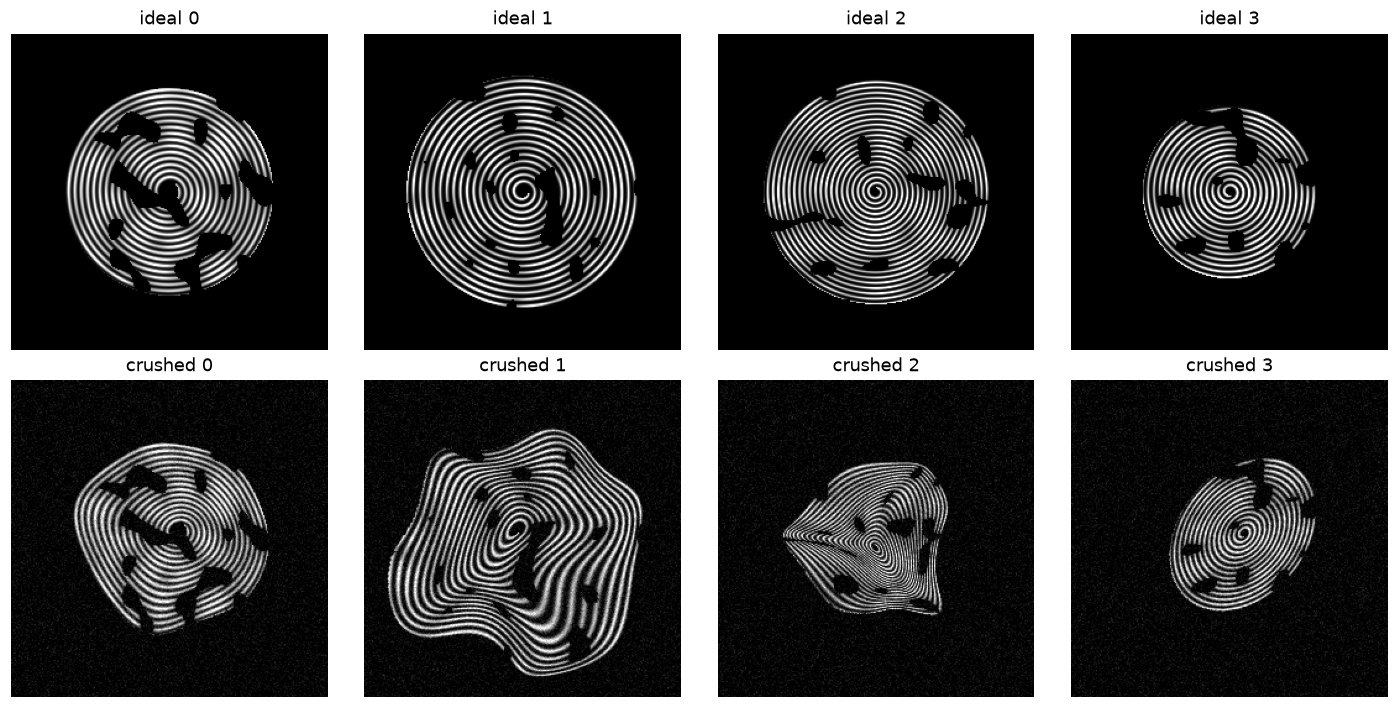

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(13, 6.5))
for i in range(4):
    ax[0, i].imshow(ideal[i, 0].cpu()); ax[1, i].imshow(deformed[i, 0].cpu())
    ax[0, i].set_title(f'ideal {i}'); ax[1, i].set_title(f'crushed {i}')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 1. A crush is a flow

`random_velocity` builds v(x) = A·x + t + smooth noise: a squash along a random axis (A symmetric, so no rotation),
a small shift, and a wobble. `flow` integrates it by **scaling and squaring**: take v / 2⁷ as a tiny displacement, then
compose the map with itself 7 times (2⁷ = 128 Euler steps for the price of 7). The grid shows what the map does to the
ideal image's coordinates.

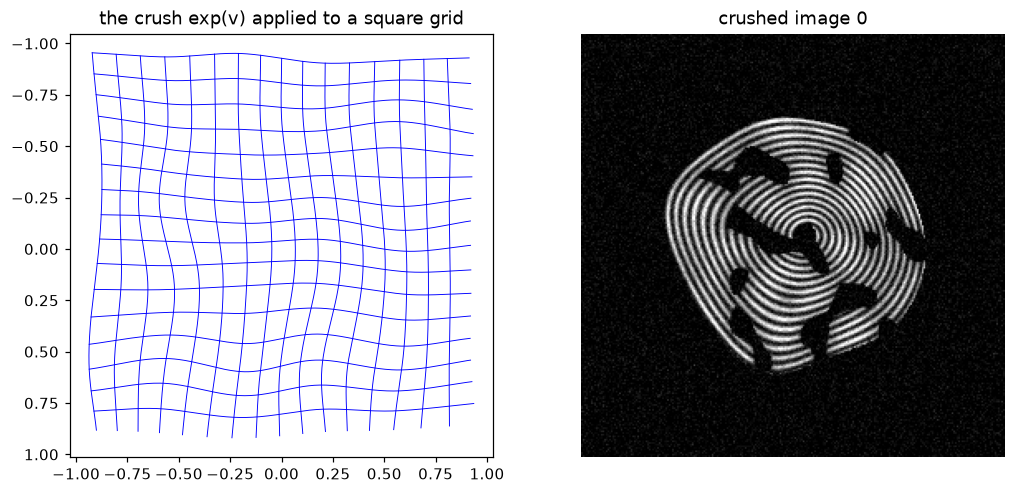

exp(v)(exp(-v)(x)) vs x: median error 0.00007, max 0.00025 (one pixel = 0.00784), on the 75% of points whose inverse stays inside the image


In [5]:
phi = fl.flow(v[:1]); back = fl.flow(-v[:1])
g = phi[0].cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for k in range(0, fl.SIZE, 16):
    ax[0].plot(g[k, :, 0], g[k, :, 1], 'b', lw=.6); ax[0].plot(g[:, k, 0], g[:, k, 1], 'b', lw=.6)
ax[0].set_aspect('equal'); ax[0].invert_yaxis(); ax[0].set_title('the crush exp(v) applied to a square grid')
ax[1].imshow(deformed[0, 0].cpu()); ax[1].set_title('crushed image 0'); ax[1].axis('off'); plt.show()
comp = fl.warp(phi.permute(0, 3, 1, 2), back).permute(0, 2, 3, 1)
inside = (back.abs() < 0.95).all(-1)
err = (comp - fl.grid())[inside].norm(dim=-1)
print(f'exp(v)(exp(-v)(x)) vs x: median error {err.median():.5f}, max {err.max():.5f} (one pixel = {2 / 255:.5f}), '
      f'on the {inside.float().mean():.0%} of points whose inverse stays inside the image')

**Counterexample: why not just predict a displacement?** A displacement field d gives the map x + d(x). Make the
deformation three times stronger and compare it with the flow of the same field.

pixels with det <= 0, per sample:  displacement ['0.9%', '23.4%', '51.8%', '0.0%'] | flow ['0.0%', '0.0%', '0.0%', '0.0%']


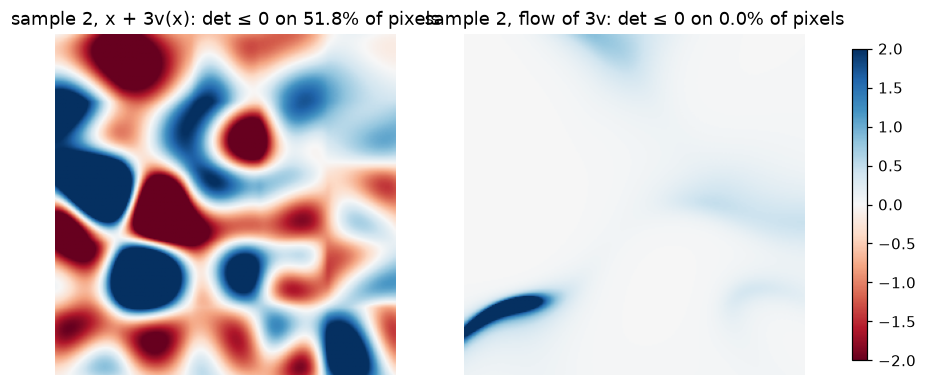

In [6]:
big = 3 * v
dd = fl.jacobian_det(fl.grid() + big.permute(0, 2, 3, 1)).cpu(); df = fl.jacobian_det(fl.flow(big)).cpu()
print('pixels with det <= 0, per sample:  displacement', [f'{f:.1%}' for f in (dd <= 0).float().mean((1, 2))],
      '| flow', [f'{f:.1%}' for f in (df <= 0).float().mean((1, 2))])
i = int((dd <= 0).float().mean((1, 2)).argmax()); det_disp, det_flow = dd[i], df[i]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, d, name in ((ax[0], det_disp, 'x + 3v(x)'), (ax[1], det_flow, 'flow of 3v')):
    im = a.imshow(d, cmap='RdBu', vmin=-2, vmax=2); a.set_title(f'sample {i}, {name}: det ≤ 0 on {(d <= 0).float().mean():.1%} of pixels'); a.axis('off')
plt.colorbar(im, ax=ax, shrink=.8); plt.show()

Red = negative determinant = the map turned the sheet inside out there: two wraps passed through each other. The
displacement folds; the flow of the same field does not, however strong.

## 2. Learn to uncrush (supervised, on synthetic pairs)

A small U-Net reads the crushed image and predicts a velocity field u. The loss compares u with the true v, and the
uncrushed image `warp(crushed, flow(u))` with the ideal. Each step draws 12 fresh pairs, so the network never sees the
same spiral twice. 3,000 steps take about 12 minutes on Apple MPS; the weights are saved under `data/cache/flow05/`
(every 250 steps, with resume), and a rerun loads them.

loaded the trained model (3000 steps)
1s


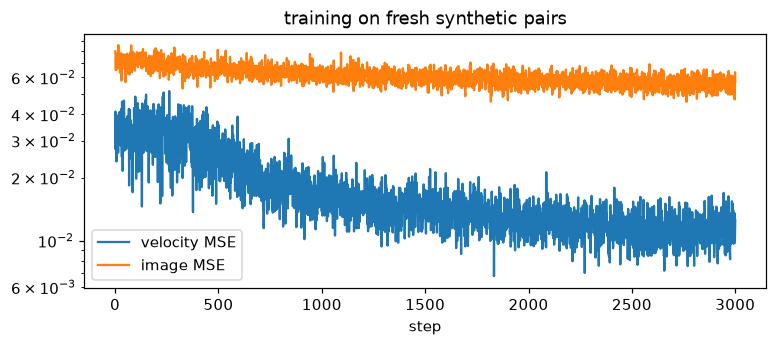

In [7]:
t = time.time(); net, hist = fl.train(); print(f'{time.time() - t:.0f}s')
H = np.array(hist)
plt.figure(figsize=(8, 3)); plt.semilogy(H[:, 0], H[:, 1], label='velocity MSE'); plt.semilogy(H[:, 0], H[:, 2], label='image MSE')
plt.xlabel('step'); plt.legend(); plt.title('training on fresh synthetic pairs'); plt.show()

**Held-out synthetic test.** New spirals and new crushes (seed 123). How close to the ideal is the crushed image, and
the uncrushed one? And the question that matters for reading a scroll: does each sheet point land on the **right wrap**?

crushed_vs_ideal         0.456
uncrushed_vs_ideal       0.588
right_wrap_before        0.130
right_wrap_after         0.224
within_one_wrap_after    0.640


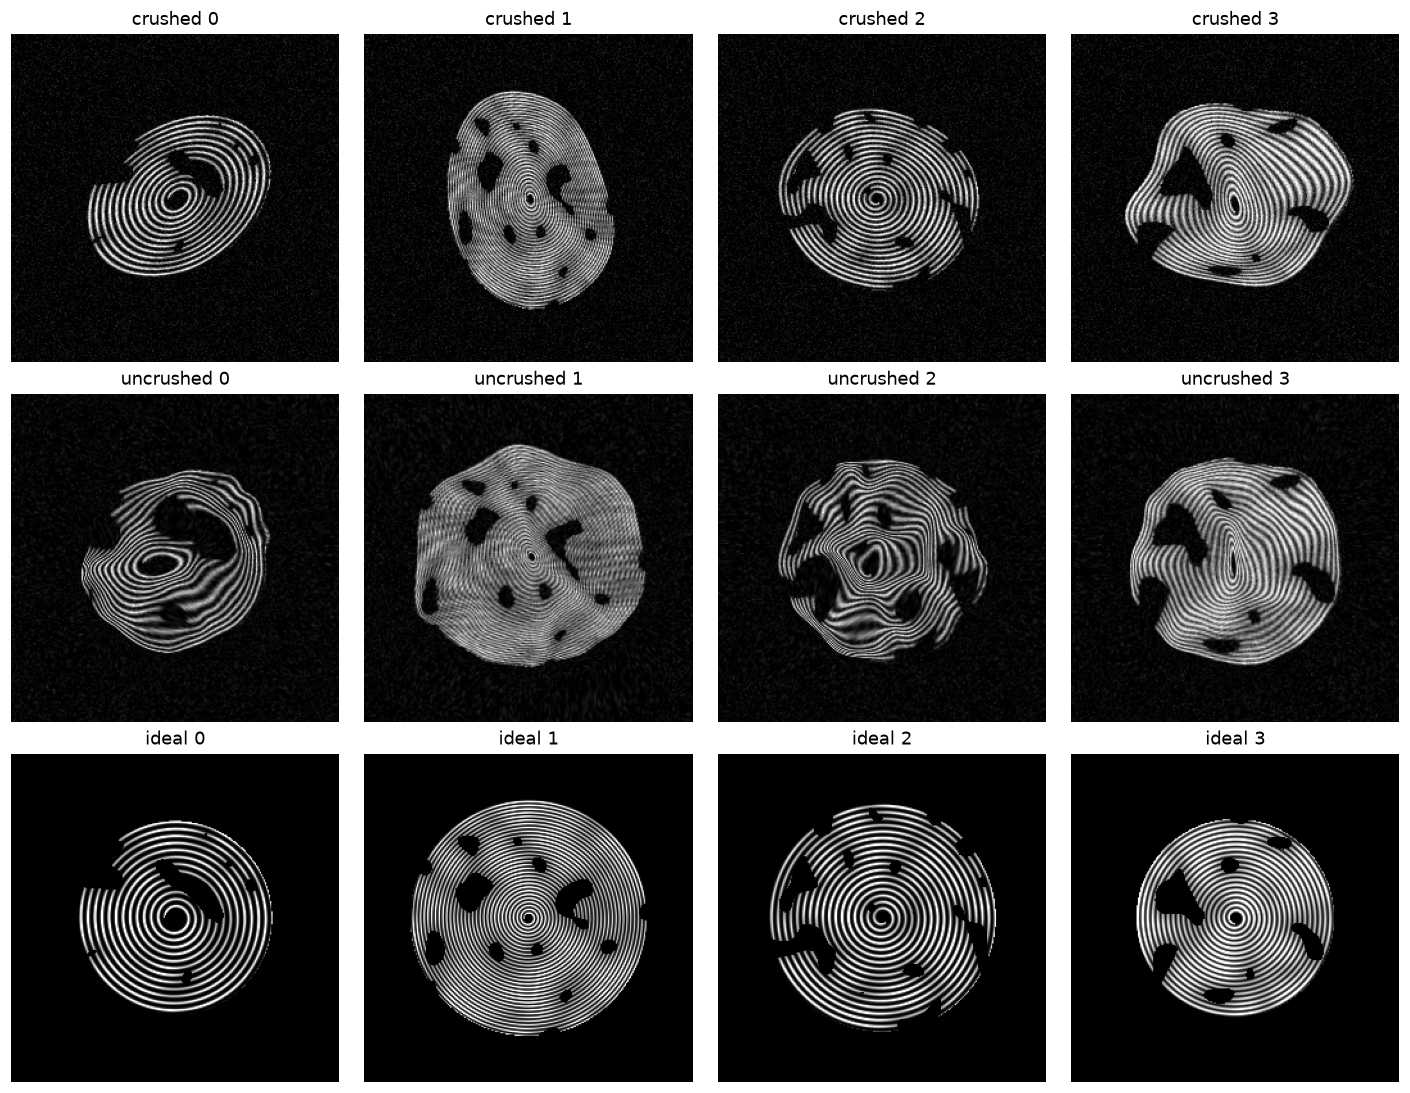

In [8]:
@torch.no_grad()
def uncrush(img):
    u = net(img); return fl.warp(img, fl.flow(u)), u

rng = np.random.default_rng(123); P = fl.spiral_params(16, rng); I0, _ = fl.spiral_image(P)
V = fl.random_velocity(16, rng); D = (fl.warp(I0, fl.flow(-V)) + 0.06 * torch.randn_like(I0)).clamp(0, 1)
U_img, U = uncrush(D)
corr = lambda a, b: float(np.corrcoef(a.cpu().numpy().ravel(), b.cpu().numpy().ravel())[0, 1])
rows = []
for i in range(16):
    x, turn = fl.spiral_points(P, i, 1500, rng)
    y = fl.at_points(fl.flow(V[i:i + 1]), x)                 # where each sheet point sits in the crushed image
    back_pts = fl.at_points(fl.flow(-U[i:i + 1]), y)         # our uncrush, applied to those points
    rows.append(dict(crushed_vs_ideal=corr(D[i], I0[i]), uncrushed_vs_ideal=corr(U_img[i], I0[i]),
                     right_wrap_before=(fl.turn_of(y, P, i) == turn).mean(), right_wrap_after=(fl.turn_of(back_pts, P, i) == turn).mean(),
                     within_one_wrap_after=(np.abs(fl.turn_of(back_pts, P, i) - turn) <= 1).mean()))
R = pd.DataFrame(rows); print(R.mean().round(3).to_string())
fig, ax = plt.subplots(3, 4, figsize=(13, 10))
for c, i in enumerate(range(4)):
    for r, (img, name) in enumerate(((D, 'crushed'), (U_img, 'uncrushed'), (I0, 'ideal'))):
        ax[r, c].imshow(img[i, 0].cpu()); ax[r, c].set_title(f'{name} {i}'); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

## 3. No pairs at all: flow matching with optimal-transport couplings

On a real scroll we have the crushed sheet and only a *description* of the ideal (a spiral), never the pairing. Flow
matching can still learn a map between two unpaired point clouds: draw a minibatch from each, pair them by **optimal
transport** (the matching that moves the least squared distance), and regress a velocity field onto the straight lines
between the pairs (OT-CFM, Tong et al. 2023). We also run exact OT on all 1,500 points, the limit the minibatches
approximate.

**The catch, predicted before running it.** OT pairs each point with the *nearest* free ideal point. A real crush is not
least-movement: squash a circle into an ellipse, and the points on the short axis are closest to an *inner* wrap of the
ideal spiral. So OT should put many points on the wrong wrap, and more so the harder the crush.

fraction of sheet points on the right wrap
        identity  exact_OT  OT_flow_matching  supervised_UNet
crush                                                        
mild        0.52      0.63              0.71             0.40
medium      0.20      0.57              0.33             0.25
hard        0.04      0.48              0.26             0.11


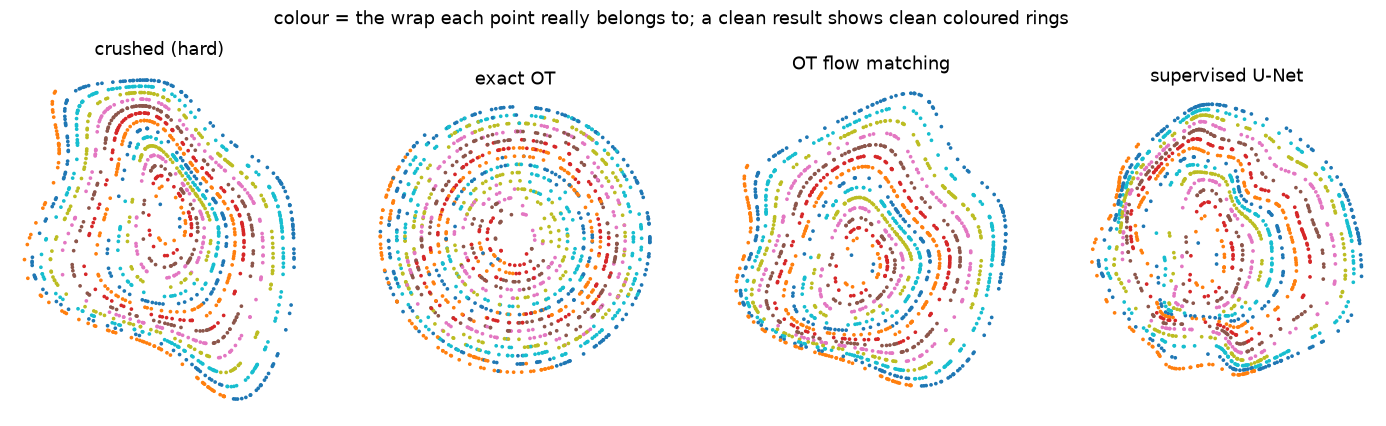

In [9]:
rows, keep = [], None
for name, crush, wob in (('mild', (0.9, 1.0), 0.0), ('medium', (0.75, 0.95), 0.06), ('hard', (0.55, 0.75), 0.12)):
    rng = np.random.default_rng(7); p = fl.spiral_params(1, rng); vv = fl.random_velocity(1, rng, crush=crush, wobble=wob)
    x, turn = fl.spiral_points(p, 0, 1500, rng); y = fl.at_points(fl.flow(vv), x)
    x_free, _ = fl.spiral_points(p, 0, 1500, rng)                       # an UNPAIRED sample of the ideal
    ot = x_free[fl.ot_pairs(y, x_free)]
    cfm = fl.transport(fl.ot_flow_matching(y, x_free, steps=1500), y)
    img = (fl.warp(fl.spiral_image(p)[0], fl.flow(-vv)) + 0.06 * torch.randn(1, 1, fl.SIZE, fl.SIZE, device=fl.DEV)).clamp(0, 1)
    sup = fl.at_points(fl.flow(-uncrush(img)[1]), y)
    ok = lambda z: (fl.turn_of(z, p, 0) == turn).mean()
    rows.append(dict(crush=name, identity=ok(y), exact_OT=ok(ot), OT_flow_matching=ok(cfm), supervised_UNet=ok(sup)))
    if name == 'hard': keep = (y, ot, cfm, sup, turn)
print('fraction of sheet points on the right wrap'); print(pd.DataFrame(rows).set_index('crush').round(2).to_string())
y, ot, cfm, sup, turn = keep
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
for a, z, name in zip(ax, (y, ot, cfm, sup), ('crushed (hard)', 'exact OT', 'OT flow matching', 'supervised U-Net')):
    a.scatter(z[:, 0], z[:, 1], c=turn % 7, cmap='tab10', s=2); a.set_aspect('equal'); a.invert_yaxis(); a.set_title(name); a.axis('off')
plt.suptitle('colour = the wrap each point really belongs to; a clean result shows clean coloured rings'); plt.show()

## 4. The real test: a crushed cross-section of PHerc. 139

A level-4 slice through the middle of the traced segment w025, and the traced sheet itself (mesh points within half a
level-4 voxel of the slice). If the network learned something about crushes in general, the traced wrap should come
out **rounder**. `roundness` fits a circle centre and a slowly growing radius, and returns the leftover wobble divided by
the radius: 0 is a perfect wrap.

slice z = 314 (level 4) | crop 272×272 -> 256 | traced points 253
roundness of the traced wrap: before 0.1961, after uncrushing 0.2334  (0 = perfect)


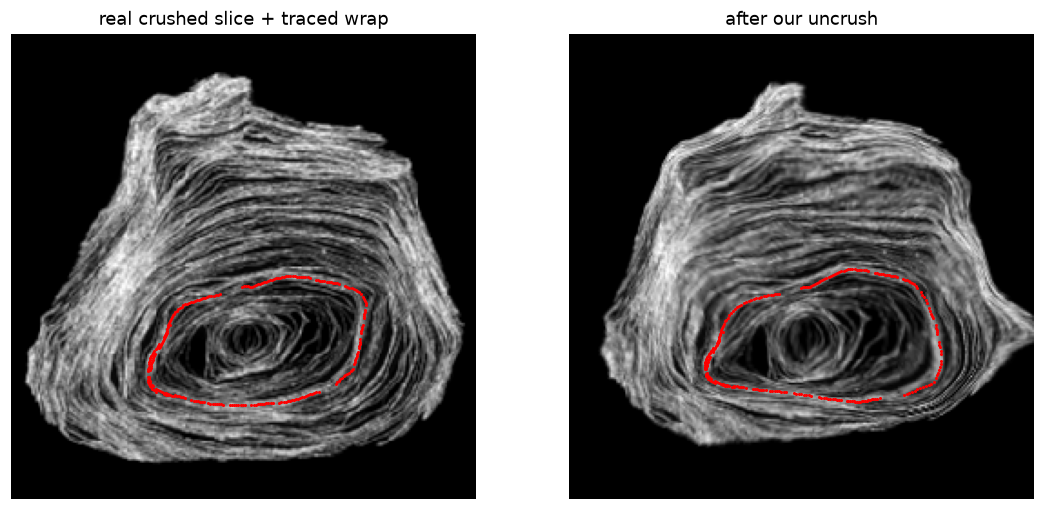

In [10]:
x, y, z, meta = vlab.segment_mesh(); m = x > 0
z0 = float(np.median(z[m])); k4 = int(round(z0 / 16))
sl = vlab.crop(vlab.scroll_volume(4), 'v4z', k4).astype(np.float32)
sel = m & (np.abs(z - z0) < 8); curve = np.stack([x[sel], y[sel]], 1) / 16          # level-0 voxels -> level 4
ys, xs = np.where(sl > np.percentile(sl[sl > 0], 30)); pad = 8
c0, r0_ = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2; half = max(xs.max() - xs.min(), ys.max() - ys.min()) / 2 + pad
x0, y0 = int(c0 - half), int(r0_ - half); side = int(2 * half)
crop_ = np.zeros((side, side), np.float32); src = sl[max(y0, 0):y0 + side, max(x0, 0):x0 + side]
crop_[max(-y0, 0):max(-y0, 0) + src.shape[0], max(-x0, 0):max(-x0, 0) + src.shape[1]] = src
lo, hi = np.percentile(crop_[crop_ > 0], [5, 99.5])
img = torch.tensor(np.clip((crop_ - lo) / (hi - lo), 0, 1), dtype=torch.float32)[None, None]
img = torch.nn.functional.interpolate(img, size=(fl.SIZE, fl.SIZE), mode='area').to(fl.DEV)
cn = ((curve - [x0, y0]) / (side - 1) * 2 - 1).astype(np.float32)                    # the traced wrap, normalised
real_un, u_real = uncrush(img)
cn_after = fl.at_points(fl.flow(-u_real), cn)
print(f'slice z = {k4} (level 4) | crop {side}×{side} -> {fl.SIZE} | traced points {len(cn)}')
print(f'roundness of the traced wrap: before {fl.roundness(cn):.4f}, after uncrushing {fl.roundness(cn_after):.4f}  (0 = perfect)')
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, im, c, name in ((ax[0], img, cn, 'real crushed slice + traced wrap'), (ax[1], real_un, cn_after, 'after our uncrush')):
    a.imshow(im[0, 0].cpu(), extent=(-1, 1, 1, -1)); a.plot(c[:, 0], c[:, 1], 'r.', ms=2); a.set_title(name); a.axis('off')
plt.show()

## 5. Reading the results

**Measured** (one training run, seed 0, 3,000 steps; held-out synthetic seed 123; OT seed 7):

| test | result |
|---|---|
| invertibility: exp(v) after exp(−v) | median error 0.00007, i.e. 1% of a pixel |
| folds at 3× strength | displacement: 0.9%, 23.4%, 51.8%, 0.0% of pixels on the four samples; flow: 0% on all |
| synthetic, image correlation with the ideal | crushed 0.456 → uncrushed 0.588 |
| synthetic, points on the **right wrap** | 13.0% before → 22.4% after; within one wrap 64.0% |
| unpaired, right wrap on a hard crush | exact OT 48%, OT flow matching 26%, supervised U-Net 11% |
| real PHerc. 139 slice, roundness of the traced wrap | 0.196 before → **0.233 after (worse)** |

1. **The flow does what it promises.** Invertible to 1% of a pixel, and never folds, even where the same field used as
   a displacement folds half the image. This part is solid.
2. **The supervised uncrusher learns the coarse shape, not the wraps.** The outline comes back round and the image
   correlation rises, but only about a fifth of the sheet points land on their own wrap. Two wraps are 2–6 pixels
   apart here; the predicted velocity is off by about 13 pixels (RMS, from the training loss). Wrap-level accuracy needs
   an error below half a wrap spacing, and this model is far from that.
3. **A trade-off we measured, not guessed.** A first version predicted the velocity at full resolution: image
   correlation 0.665 but only 14.3% on the right wrap, and smeared images, because pixel-level noise in u scrambles the
   sheet. Predicting u on a 16 × 16 grid (this version) lowers the image score to 0.588 but raises the right-wrap
   fraction to 22.4% (within one wrap: 40.8% → 64.0%). A crush is smooth; the model should be too.
4. **OT beat the U-Net on wraps, but the comparison flatters OT.** It was given an exact sample of the *true* ideal
   spiral (its spacing, centre and start angle), which the U-Net never sees. Even so, on a hard crush it put 52% of the
   points on the wrong wrap while drawing perfect-looking rings: the plot looks solved and is half wrong. That is the
   catch of least-movement matching, and why the spiral fit relies on winding constraints rather than on matching alone.
5. **The real test failed.** On the real slice the traced wrap came out *less* round (0.196 → 0.233). The synthetic
   spirals are thin bright lines on black; the real cross-section is dense grey papyrus with a crushed, lumpy outline
   and about 30–50 wraps (notebook 00). The network learned the inverse of *our* simulator, which is exactly the worry
   in the opening question, and the real data is outside it.

**What would have to change for this to work on real scans**, as hypotheses to test (HYPOTHESIS, unverified):

- a simulator closer to the scan: real wrap spacing and count, grey papyrus texture, touching and delaminated wraps,
  the scan's noise, and domain randomisation wide enough that the real slice is one case among many;
- an error measured in wrap spacings, and a loss that punishes wrap swaps directly (for example, a winding-number term);
- using the network only as the **initial guess** for the challenge's per-scroll spiral fit, which then corrects it
  against real constraints: amortised inference plus refinement, rather than either alone.

## Ideas to try

1. Train on spirals with 30–50 wraps and real-looking texture (sample patches of the real scan as the fill).
2. Feed two inputs: the image and a structure-tensor normal field (notebook 01), so the network sees sheet direction.
3. Add a few winding constraints as an extra input channel: does 1% of annotated points fix the wrap error?
4. Replace the U-Net with OT flow matching conditioned on the image.

## Check yourself

1. Why is the inverse of exp(v) exactly exp(−v) for a stationary velocity field, and why is that not true for a
   displacement field?
2. Why do trajectories of a flow never cross, and why does that stop two wraps passing through each other?
3. The OT result drew perfect rings with half the points on the wrong ring. Why does least-movement matching produce
   that?
4. Why did predicting the velocity on a coarse grid lower the image score but raise the wrap score?
5. What does the failed real test tell you about the simulator, and what is the cheapest change to test first?